# Nursing Homes Operations in Ireland

## 1. Project Overview

This module focuses on nursing homes in Ireland and their role in providing long-term residential care for older people.

After exploring population growth, functional limitations and Home Support services in the previous modules, I now want to understand the residential side of long-term care.

The main goal is to investigate how nursing home capacity is distributed across Ireland and how it has changed over time.

## 2. Main Research Question

**Is nursing home capacity in Ireland keeping pace with the growing older population?**

To explore this question, I will focus on the number of registered nursing homes, their available capacity and the historical development of long-term care beds.

I will also consider the demographic findings from the first module to provide context for the analysis.

## 3. Data Sources

For this module, I selected two official data sources:

**HIQA — Register of Nursing Homes**

This dataset contains information about registered nursing homes in Ireland, including facility names, locations and maximum occupancy.

It will be used to explore the distribution of registered nursing homes and their capacity.

Source: [HIQA — Nursing Homes](https://www.hiqa.ie/areas-we-work/nursing-homes)

**Department of Health — JQ17: Long-term Care Nursing Beds**

This dataset provides historical information about long-term care nursing beds in Ireland, covering the period from 1987 to 2025.

It will be used to understand how the national number of beds has changed over time.

Source: [Department of Health — JQ17 CSV](https://assets.gov.ie/static/documents/7e1ab8df/JQ17_-_Long-term_care_nursing_beds.csv)

## 4. Initial Analysis Plan

I will begin by exploring the structure and quality of both datasets before deciding which indicators to calculate.

The initial analysis will focus on:

- Number of registered nursing homes.
- Registered capacity across facilities.
- Distribution of nursing homes by county or region, depending on the available information.
- Historical changes in the number of long-term care beds.
- Comparison with the growth of the older population.

## 5. Scope and Limitations

The two datasets provide different types of information.

The HIQA register contains facility-level information, while the JQ17 dataset provides historical national figures.

Therefore, I will first analyse them separately and only combine information if the definitions, periods and level of detail are compatible.

Registered capacity should not automatically be interpreted as the number of occupied beds. Similarly, the number of beds does not represent the total number of people receiving long-term care.

These differences will be considered when interpreting the results.


In [1]:
import pdfplumber
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df_nursing_beds = pd.read_csv('../data/raw/JQ17_-_Long-term_care_nursing_beds.csv')

df_nursing_beds.head()

,STATISTIC,Statistic Label,YEAR,Year,BEDTYPE,Bed type,UNIT,VALUE,FLAG,Flag
0,LTCBEDS,Beds in residential long-term care facilities,1987,1987,NURSING,Long-term care nursing bed,Number,9400,NaN,NaN
1,LTCBEDS,Beds in residential long-term care facilities,1988,1988,NURSING,Long-term care nursing bed,Number,9450,NaN,NaN
2,LTCBEDS,Beds in residential long-term care facilities,1989,1989,NURSING,Long-term care nursing bed,Number,11443,NaN,NaN
3,LTCBEDS,Beds in residential long-term care facilities,1990,1990,NURSING,Long-term care nursing bed,Number,11195,NaN,NaN
4,LTCBEDS,Beds in residential long-term care facilities,1991,1991,NURSING,Long-term care nursing bed,Number,11600,NaN,NaN


In [3]:
df_nursing_homes = pd.read_csv('../data/raw/HIQA_Nursing_Homes.csv')

df_nursing_homes.head()

,Centre_ID,Centre_Title,Centre_Address,County,Maximum_Occupancy,Centre_Phone,Person_in_Charge,Person_in_Charge_Phone,Registration_Provider,Registration_Provider_Address,Registration_Provider_Phone,Registration_Date,Registration_Expiry_Date,Expiry_Date_Note,CRO_Registration_Number,Management_Contacts,Registration_Number,Chief_Inspector_Note,Registration_Conditions,URL
0,738,Abbey Haven Care Centre & Nursing Home,"Saint Joseph's Avenue, Boyle, F52 AX24",Roscommon,63,071 967 0111,Breda Casey,071 967 0111,Abbey Haven Care Centre & Nursing Home Limited,"Carrick Road, Boyle, F52 AX24, Roscommon",071 967 0111,01-03-2024,28-02-2027,NaN,675830,Breege Mulryan - 071 967 0111,REG-0038082,NaN,Condition 1 Subject to any prohibitions or res...,https://www.hiqa.ie/areas-we-work/find-a-centr...
1,308,AbbeyBreaffy Nursing Home,"Dublin Road (N5), Castlebar, F23 NY75",Mayo,55,094 902 5029,Selda Susan Babu,094 902 5029,Knegare Nursing Home Holdings Ltd,"Talbot Lodge, 17 Kinsealy Lane, Malahide, K36 ...",01 846 2115,27-12-2025,26-12-2028,NaN,643413,"Denise Steed O Doherty - 086 215 1054, Mairead...",REG-0041188,NaN,Condition 1 Subject to any prohibitions or res...,https://www.hiqa.ie/areas-we-work/find-a-centr...
2,743,Abbeygale House,"Farnogue Residential Unit, Old Hospital Road, ...",Wexford,30,053 915 7821,Julia Miller,053 915 782,Health Service Executive,"Oak House, Millennium Park, Naas, W91 KDC2, Ki...",045 880 400,04-06-2025,03-06-2028,NaN,NaN,NaN,REG-0040306,NaN,Condition 1 Subject to any prohibitions or res...,https://www.hiqa.ie/areas-we-work/find-a-centr...
3,187,Abbeylands Nursing Home,"Carhoo, Kildorrery, P67 NH76",Cork,50,022 250 90,Joys George,022 250 90,Abbeylands Nursing Home & Alzheimer Unit Limited,"Carhoo, Kildorrery, P67 NH76, Cork",022 25 090,31-05-2026,30-05-2029,NaN,448593,NaN,REG-0041818,NaN,Condition 1 Subject to any prohibitions or res...,https://www.hiqa.ie/areas-we-work/find-a-centr...
4,4682,Abbot Close Care Centre,"St. Marys Terrace, Askeaton, V94 F864",Limerick,65,061 601 888,Catherine Lynch (Deputising) for Camilla Pop (...,087 4897030,Abbot Close Nursing Home Ltd,"Market House, Churchtown, Mallow, P51 NH6X, Cork",022 346 93,16-06-2024,15-06-2027,NaN,525869,"Airida Downes - 022 34693, Deirdre Vaughan - 0...",REG-0038665,NaN,Condition 1 Subject to any prohibitions or res...,https://www.hiqa.ie/areas-we-work/find-a-centr...


In [4]:
df_nursing_beds.shape

(39, 10)

In [5]:
df_nursing_beds.info()

<class 'pandas.DataFrame'>
RangeIndex: 39 entries, 0 to 38
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   STATISTIC        39 non-null     str  
 1   Statistic Label  39 non-null     str  
 2   YEAR             39 non-null     int64
 3   Year             39 non-null     int64
 4   BEDTYPE          39 non-null     str  
 5   Bed type         39 non-null     str  
 6   UNIT             39 non-null     str  
 7   VALUE            39 non-null     int64
 8   FLAG             3 non-null      str  
 9   Flag             3 non-null      str  
dtypes: int64(3), str(7)
memory usage: 3.2 KB


In [6]:
df_nursing_beds[['YEAR', 'VALUE', 'FLAG', 'Flag']].tail(10)

,YEAR,VALUE,FLAG,Flag
29,2016,30396,NaN,NaN
30,2017,30732,NaN,NaN
31,2018,31251,NaN,NaN
32,2019,32071,NaN,NaN
33,2020,32104,NaN,NaN
34,2021,31842,NaN,NaN
35,2022,31674,NaN,NaN
36,2023,32155,NaN,NaN
37,2024,32169,NaN,NaN
38,2025,32233,NaN,NaN


In [7]:
df_nursing_beds['FLAG'].value_counts(dropna=False)

FLAG
NaN    36
B       3
Name: count, dtype: int64

In [8]:
df_nursing_beds.loc[df_nursing_beds['FLAG'].notna(), ['YEAR', 'VALUE', 'FLAG', 'Flag']]

,YEAR,VALUE,FLAG,Flag
22,2009,28758,B,Break in series
23,2010,26087,B,Break in series
27,2014,28705,B,Break in series


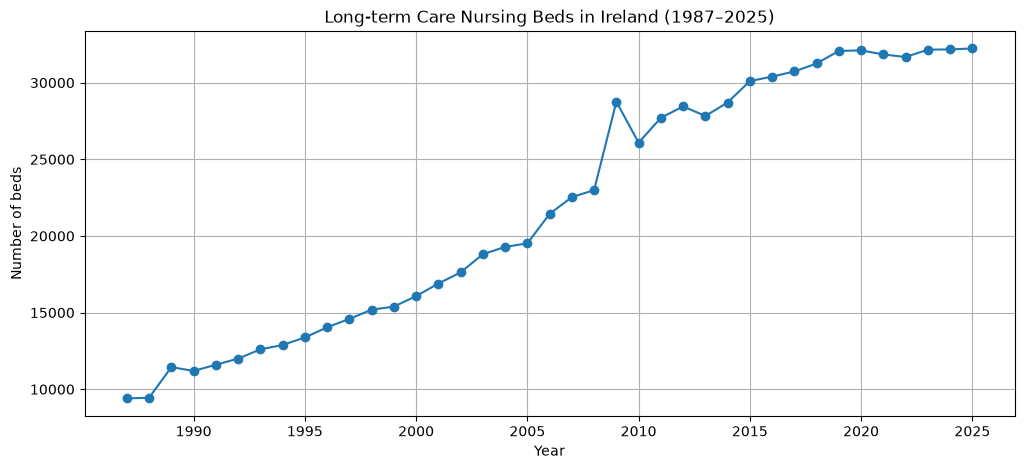

In [9]:
plt.figure(figsize=(12, 5))

plt.plot(
    df_nursing_beds['YEAR'],
    df_nursing_beds['VALUE'],
    marker='o'
)

plt.title('Long-term Care Nursing Beds in Ireland (1987–2025)')
plt.xlabel('Year')
plt.ylabel('Number of beds')
plt.grid(True)
plt.show()

In [10]:
df_nursing_beds.columns

Index(['STATISTIC', 'Statistic Label', 'YEAR', 'Year', 'BEDTYPE', 'Bed type',
       'UNIT', 'VALUE', 'FLAG', 'Flag'],
      dtype='str')

In [12]:
df_nursing_beds.columns = (
    df_nursing_beds.columns
    .str.strip()
    .str.lower()
    .str.replace(' ', '_')
)

df_nursing_beds.columns

Index(['statistic', 'statistic_label', 'year', 'year', 'bedtype', 'bed_type',
       'unit', 'value', 'flag', 'flag'],
      dtype='str')

In [13]:
df_nursing_beds.columns = [
    'statistic',
    'statistic_label',
    'year_code',
    'year',
    'bedtype',
    'bed_type',
    'unit',
    'value',
    'flag_code',
    'flag_description'
]

df_nursing_beds.info()

<class 'pandas.DataFrame'>
RangeIndex: 39 entries, 0 to 38
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   statistic         39 non-null     str  
 1   statistic_label   39 non-null     str  
 2   year_code         39 non-null     int64
 3   year              39 non-null     int64
 4   bedtype           39 non-null     str  
 5   bed_type          39 non-null     str  
 6   unit              39 non-null     str  
 7   value             39 non-null     int64
 8   flag_code         3 non-null      str  
 9   flag_description  3 non-null      str  
dtypes: int64(3), str(7)
memory usage: 3.2 KB


In [14]:
df_nursing_beds.head()

,statistic,statistic_label,year_code,year,bedtype,bed_type,unit,value,flag_code,flag_description
0,LTCBEDS,Beds in residential long-term care facilities,1987,1987,NURSING,Long-term care nursing bed,Number,9400,NaN,NaN
1,LTCBEDS,Beds in residential long-term care facilities,1988,1988,NURSING,Long-term care nursing bed,Number,9450,NaN,NaN
2,LTCBEDS,Beds in residential long-term care facilities,1989,1989,NURSING,Long-term care nursing bed,Number,11443,NaN,NaN
3,LTCBEDS,Beds in residential long-term care facilities,1990,1990,NURSING,Long-term care nursing bed,Number,11195,NaN,NaN
4,LTCBEDS,Beds in residential long-term care facilities,1991,1991,NURSING,Long-term care nursing bed,Number,11600,NaN,NaN


In [17]:
columns_to_check = [
    'statistic',
    'statistic_label',
    'year_code',
    'bedtype',
    'bed_type',
    'unit'
]

for column in columns_to_check:
    print(f'{column}: {df_nursing_beds[column].nunique()} unique values')

statistic: 1 unique values
statistic_label: 1 unique values
year_code: 39 unique values
bedtype: 1 unique values
bed_type: 1 unique values
unit: 1 unique values


In [19]:
print((df_nursing_beds['year_code'] == df_nursing_beds['year']).all())

True


In [20]:
df_nursing_beds_clean = df_nursing_beds[
    ['year', 'value', 'flag_code', 'flag_description']
].copy()

In [21]:
df_nursing_beds_clean.head()

,year,value,flag_code,flag_description
0,1987,9400,NaN,NaN
1,1988,9450,NaN,NaN
2,1989,11443,NaN,NaN
3,1990,11195,NaN,NaN
4,1991,11600,NaN,NaN


In [22]:
df_nursing_beds_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 39 entries, 0 to 38
Data columns (total 4 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   year              39 non-null     int64
 1   value             39 non-null     int64
 2   flag_code         3 non-null      str  
 3   flag_description  3 non-null      str  
dtypes: int64(2), str(2)
memory usage: 1.3 KB
